# Project: Whale migration Analysis

**Hypotheses:** Does whale movement depend on water temperature between Antarctica and the South Pole?

**Data:** Movebank (open source), NOAA.

_Note: The data was loaded from a private Google Drive. To run this notebook, please download the CSV file from the repository and update the file path in the code below._

In [1]:
from google.colab import drive
drive.mount("/content/drive/")

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


To begin, I imported the pandas library, which I used to load the downloaded CSV file with whale tracking data.

I also imported matplotlib in advance for data visualization.

In [2]:
import pandas as pd

In [3]:
import matplotlib.pyplot as plt

In [4]:
df_whales = pd.read_csv("/content/drive/MyDrive/MarineProject_10.26.26/Antarctic blue whales, east Antarctic sector of the Southern Ocean.csv")

I created a new variable and made a copy of my whale data to clean the two selected columns from empty rows.

In [5]:
df_whales_clean = df_whales.dropna(subset=['location-long', 'location-lat']).copy()

Then I rounded the values in ['location-long'] and ['location-lat'], saving them into new columns ['long_round'] and ['lat_round'].

This is necessary for future merging with the water temperature data.

In [6]:
df_whales_clean['long_round'] = df_whales_clean['location-long'].round()
df_whales_clean['lat_round'] = df_whales_clean['location-lat'].round()

I displayed the first 5 rows to check if the rounding worked correctly.

In [7]:
df_whales_clean[['location-long','location-lat', 'long_round', 'lat_round']].head()

,location-long,location-lat,long_round,lat_round
0,169.011,-64.172,169.0,-64.0
4,169.074,-64.187,169.0,-64.0
7,169.142,-64.191,169.0,-64.0
8,169.116,-64.217,169.0,-64.0
9,169.103,-64.242,169.0,-64.0


Next, using a Linux command, I downloaded a second file containing water temperature data for 2013 (the year the whales were tracked) and gave it a short name.

In [8]:
!wget -O sst_2013.nc "https://downloads.psl.noaa.gov/Datasets/noaa.oisst.v2.highres/sst.day.mean.2013.nc"

--2026-11-05 06:40:30--  https://downloads.psl.noaa.gov/Datasets/noaa.oisst.v2.highres/sst.day.mean.2013.nc
Resolving downloads.psl.noaa.gov (downloads.psl.noaa.gov)... 140.172.38.87
Connecting to downloads.psl.noaa.gov (downloads.psl.noaa.gov)|140.172.38.87|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 474202360 (452M) [application/x-netcdf]
Saving to: ‘sst_2013.nc’

sst_2013.nc         100%[===================>] 452.23M  14.0MB/s    in 20s     

2026-11-05 06:40:55 (22.7 MB/s) - ‘sst_2013.nc’ saved [474202360/474202360]



Because the file turned out to be very large and multi-dimensional, I imported a new library to handle this format.

In [9]:
import xarray as xr

I opened the file with this library and created a new variable for the water data.

In [10]:
ds = xr.open_dataset('sst_2013.nc')

I extracted the sea surface temperature and indexed it by the given coordinates, cutting out the latitudes of Antarctica and the South Pole (while taking longitude across the globe).

Then I converted this into a simple 2D table and moved the index strings into regular columns.

In [11]:
df_water = ds['sst'].sel(lat=slice(-75, -50), lon=slice(0, 360)).to_dataframe().reset_index()

I cleaned the water data from empty values and rounded the coordinates in the same way as the whale data, so they could be merged.

In [12]:
df_water = df_water.dropna()

In [13]:
df_water['lat_round'] = df_water['lat'].round()
df_water['lon_round'] = df_water['lon'].round()

The output shows a table with rounded dates, longitude, latitude, and temperature.

In [14]:
df_water.head()

,time,lat,lon,sst,lat_round,lon_round
655,2013-01-01,-74.875,163.875,-0.66,-75.0,164.0
656,2013-01-01,-74.875,164.125,-0.65,-75.0,164.0
657,2013-01-01,-74.875,164.375,-0.60,-75.0,164.0
658,2013-01-01,-74.875,164.625,-0.64,-75.0,165.0
659,2013-01-01,-74.875,164.875,-0.69,-75.0,165.0


Before merging the two datasets, I took the time from the whale table and converted the text string into a proper date format, resetting the time to midnight.

In [15]:
df_whales_clean['time'] = pd.to_datetime(df_whales_clean['timestamp']).dt.normalize()

Then I renamed the ['long_round'] column to ['lon_round'] so the column names would match and prevent merge errors.

In [16]:
df_whales_clean = df_whales_clean.rename(columns={'long_round': 'lon_round'})

I created a final variable to merge the data from both tables (whales and water), matching them by three conditions:  time,  lon_round, and lat_round.
Only rows with an exact match in both tables were included in the new variable.

In [17]:
df_merged = pd.merge(df_whales_clean, df_water, on=['time', 'lon_round', 'lat_round'], how='inner')

The result is a table with matching values in three columns, plus the sst (temperature) column.



In [18]:
df_merged[['timestamp', 'lat_round', 'lon_round', 'sst']].head()

,timestamp,lat_round,lon_round,sst
0,2013-03-08 05:45:10.000,-64.0,169.0,0.26
1,2013-03-08 05:45:10.000,-64.0,169.0,0.29
2,2013-03-08 05:45:10.000,-64.0,169.0,0.27
3,2013-03-08 05:45:10.000,-64.0,169.0,0.24
4,2013-03-08 05:45:10.000,-64.0,169.0,0.37


I grouped the data by the square coordinates and left only the temperature column in each square to calculate the average (mean) value for each area.

In [19]:
df_merged.groupby(['lon_round', 'lat_round'])['sst'].mean()

lon_round  lat_round
74.0       -63.0       -0.564148
75.0       -63.0       -0.553125
76.0       -63.0       -0.679375
77.0       -63.0       -0.547188
78.0       -63.0       -0.470000
                          ...   
178.0      -67.0       -1.226250
179.0      -68.0       -1.453372
           -67.0       -1.072569
180.0      -68.0       -1.543750
           -67.0       -0.813125
Name: sst, Length: 85, dtype: float32

I then merged these calculated temperatures with the whale count data to output the final table.

For example, we can see that at latitude 74.0 and longitude -63.0, the temperature was -0.564148.

In [20]:
temp_by_square = df_merged.groupby(['lon_round', 'lat_round'])['sst'].mean().reset_index()

In [21]:
temp_by_square.head()

,lon_round,lat_round,sst
0,74.0,-63.0,-0.564148
1,75.0,-63.0,-0.553125
2,76.0,-63.0,-0.679375
3,77.0,-63.0,-0.547188
4,78.0,-63.0,-0.470000


I merged the updated data again and counted the total number of records inside each created coordinate group, giving the new column the name "count".

In [22]:
counts = df_merged.groupby(['lon_round', 'lat_round']).size().reset_index(name='count')

Now we can see the squares and the number of whales that passed through these latitudes.

In [23]:
counts

,lon_round,lat_round,count
0,74.0,-63.0,176
1,75.0,-63.0,32
2,76.0,-63.0,64
3,77.0,-63.0,64
4,78.0,-63.0,96
...,...,...,...
80,178.0,-67.0,192
81,179.0,-68.0,688
82,179.0,-67.0,144
83,180.0,-68.0,384


Next, I joined the final tables by rows.

In [24]:
final_squares = pd.merge(temp_by_square, counts, on=['lon_round', 'lat_round'])

I created **x** _(using the count squares)_ and **y** _(using sst)._

In [25]:
x = final_squares['count']
y = final_squares['sst']

Finally, I created a 10x6 figure to display these points, labeling the three axes of the raw table.

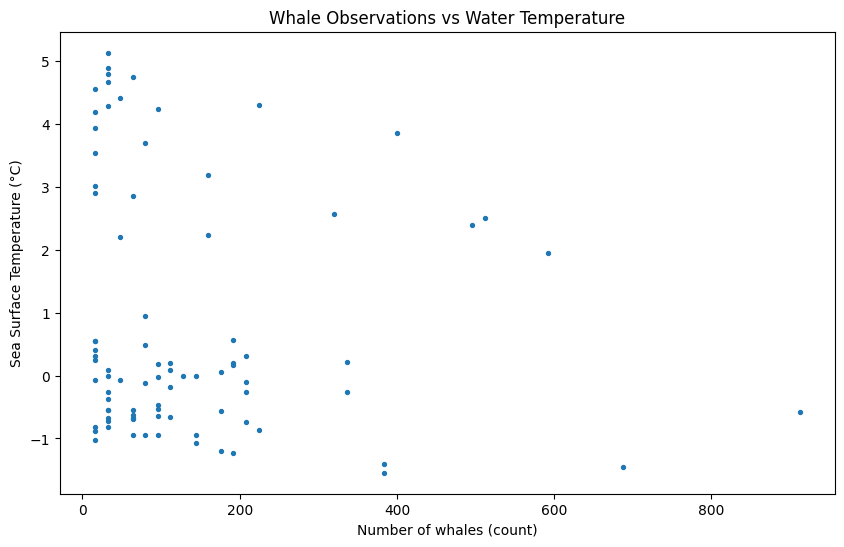

In [26]:
plt.figure(figsize=(10, 6))
plt.scatter(x, y, s=8)
plt.xlabel('Number of whales (count)')
plt.ylabel('Sea Surface Temperature (°C)')
plt.title('Whale Observations vs Water Temperature')
plt.show()

I imported a library for professional statistical visualization, called it heatmap, and pivoted the table.

In [27]:
import seaborn as sns

This made latitudes the rows, longitudes the columns, and the intersections represented the number of whales.

In [28]:
heatmap_data = final_squares.pivot(index='lat_round', columns='lon_round', values='count')

I sorted the rows in descending order and displayed the updated heatmap.

In [29]:
heatmap_data = heatmap_data.sort_index(ascending=False)

 It is sized 13x6, using red, orange, and yellow colors to indicate whale aggregations (the brighter the color, the more frequently they were recorded in the data points). I titled it "Heatmap of whale observations", "Latitude", "Longitude".

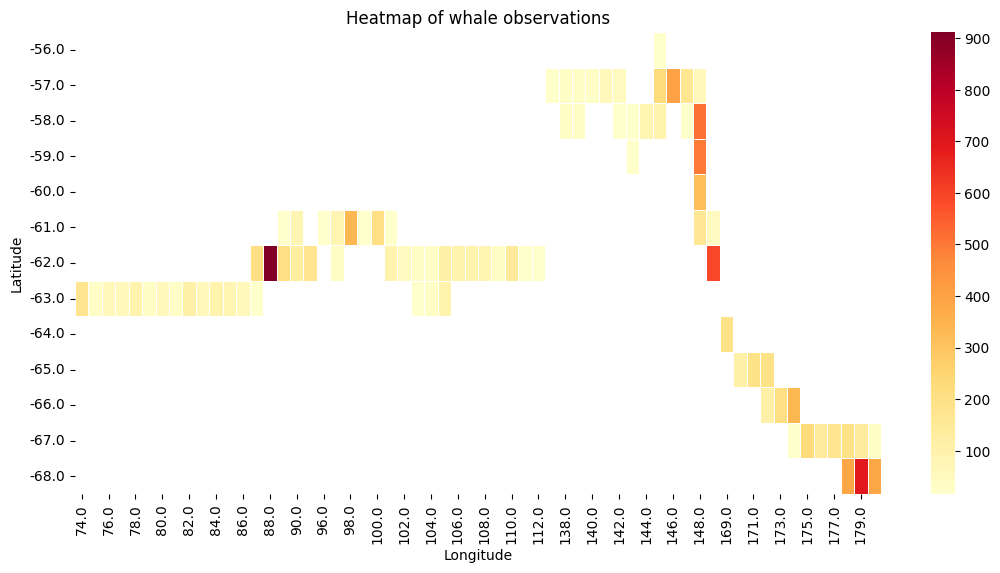

In [30]:
plt.figure(figsize=(13, 6))
sns.heatmap(heatmap_data, cmap='YlOrRd', linewidths=0.5)
plt.title('Heatmap of whale observations')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

# Conclusion:
**Answering my hypothesis:** No, water temperature does not influence whale movement, as the tables showed.
We can see that they move chaotically and aggregations rarely occur.


I believe that 808 whale records and data for only 2013 (with the caveat that only surface water was measured) are insufficient to make a strong counter-conclusion. Their movement might also be influenced by depth, food availability in the water, and the presence of predators.



## What could be improved:
- Work with a larger dataset of whale records.
- Work with data specifically in the latitudes where the whales traveled, to understand the internal environment of the water.


